In [3]:
import numpy as np
import cv2

IMG = r"C:\Users\SHUS\Desktop\cup_shots\cup.jpg"
BG  = r"C:\Users\SHUS\Desktop\cup_shots\bg.jpg"
ROI = (700, 800, 400, 700)

# ① 读图 + 裁剪
img = cv2.imread(IMG)
bg  = cv2.imread(BG)
print("img", img.shape, "bg", bg.shape)
x, y, w, h = ROI
cup_c = img[y:y+h, x:x+w]
bg_c  = bg[y:y+h, x:x+w]
print("crop", cup_c.shape, bg_c.shape)

img (2364, 1773, 3) bg (2364, 1773, 3)
crop (700, 400, 3) (700, 400, 3)


Usable
accross:577
width:248
left:87,right:233


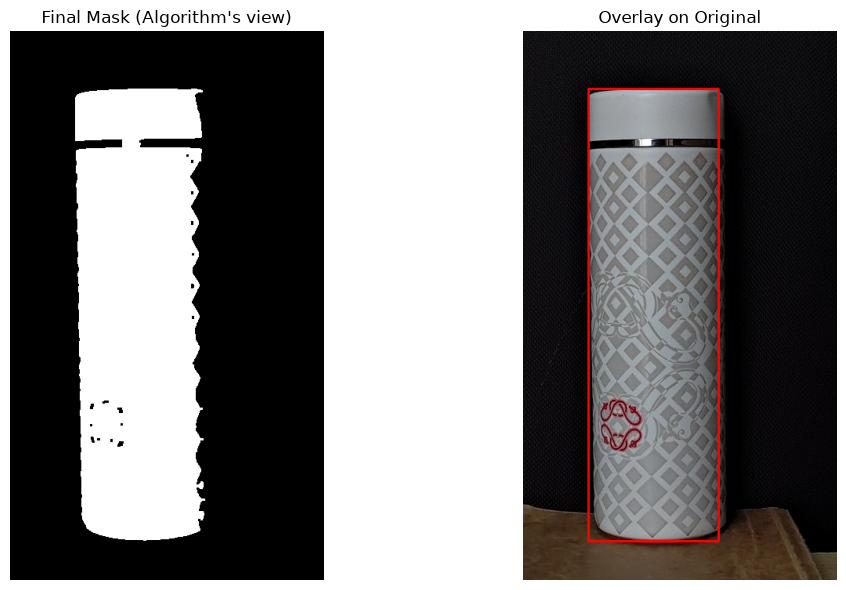

In [13]:
# ② 灰度 + 模糊
g1 = cv2.cvtColor(cup_c, cv2.COLOR_BGR2GRAY)
g2 = cv2.cvtColor(bg_c,  cv2.COLOR_BGR2GRAY)
g1 = cv2.GaussianBlur(g1, (5, 5), 0)
g2 = cv2.GaussianBlur(g2, (5, 5), 0)

# ③ 差分
diff=cv2.absdiff(g1,g2)
# ④ Otsu
t,mask=cv2.threshold(diff,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)
# ⑤ 形态
# 打印：开运算前后白色像素数，看看掉了多少
k=np.ones((3,3),np.uint8)
mask=cv2.morphologyEx(mask,cv2.MORPH_CLOSE,k)
mask=cv2.morphologyEx(mask,cv2.MORPH_OPEN,k)
# ⑥ 连通域
# 打印：一共几个连通域，选中的 area
n,lables,stats,centroid=cv2.connectedComponentsWithStats(mask,connectivity=8)
areas=stats[1:,4]
best=1+int(np.argmax(areas))
mask2=(lables==best).astype(np.uint8)*255
x,y,w,h,area=stats[best]
H,W=mask.shape
touches=(x<=1)or(y<=1)or(x+w>=W-1)or(y+h>=H-1)
if touches:
    print("Useless")
else:
    print("Usable")
# ⑦ 逐行扫描
# 打印：行范围、行跨度、最大行宽、第 300 行的左右边缘
if not touches:
    lefts=[]
    rights=[]
    rows=[]
    for yy in range(mask2.shape[0]):
        xs=np.nonzero(mask2[yy])[0]
        if xs.size==0:
            continue
        left,right=int(xs.min()),int(xs.max())
        rows.append(yy)
        lefts.append(left)
        rights.append(right)
    if len(rows)>0:
        y_min=rows[0]
        y_max=rows[-1]
        print(f"accross:{y_max-y_min+1}")
        width=[r-1+1 for l,r in zip(lefts,rights)]
        max_w=max(width)
        print(f"width:{max_w}")
        if 300 in rows:
            idx=rows.index(300)
            print(f"left:{lefts[idx]},right:{rights[idx]}")
        
   
    
# ⑧ overlay 叠加可视化
import matplotlib.pyplot as plt

# 1. 准备画布：复制一份原图（千万别在原图上直接画，会污染原数据）
overlay_img = cup_c.copy()

# 2. 开始画图（前提是前面判定目标可用，且找到了边界）
if not touches and n > 1:
    # (A) 画红色的包围框 bbox
    # 参数：图像, 左上角(x,y), 右下角(x+w, y+h), 颜色(BGR:红), 线宽
    cv2.rectangle(overlay_img, (x, y), (x+w, y+h), (0, 0, 255), 2)
    
    # (B) 画出第 300 行的左右边缘（画两个蓝色的实心小圆点）
    # 前提是第 300 行确实有边缘点（前面的代码算出过 left_edge 和 right_edge）
    if 'left_edge' in locals() and 'right_edge' in locals():
        # 参数：图像, 圆心(x,y), 半径, 颜色(BGR:蓝), 线宽(-1表示实心)
        cv2.circle(overlay_img, (left_edge, 300), 4, (255, 0, 0), -1)
        cv2.circle(overlay_img, (right_edge, 300), 4, (255, 0, 0), -1)

# 3. 颜色转换 (OpenCV 是 BGR，Matplotlib 是 RGB，直接显示会变阿凡达色)
img_rgb = cv2.cvtColor(overlay_img, cv2.COLOR_BGR2RGB)

# 4. 用 Matplotlib 并排显示两张图（左边看掩膜，右边看叠加）
plt.figure(figsize=(12, 6))

# 左图：最终的 Mask2
plt.subplot(1, 2, 1)
plt.title("Final Mask (Algorithm's view)")
# cmap='gray' 告诉画图软件这是黑白图
plt.imshow(mask2 if not touches else mask, cmap='gray') 
plt.axis('off')

# 右图：带有框和点的原图
plt.subplot(1, 2, 2)
plt.title("Overlay on Original")
plt.imshow(img_rgb)
plt.axis('off')

plt.tight_layout()
plt.show()